# 02 - HAM10000 baseline A0-A2 (lesion-safe split v2)

**Purpose:** Baseline for the class-imbalance direction (arms A0–A2).  
Every arm uses the same backbone, preprocessing, optimizer, budget and model-selection rule, only the imbalance strategy changes.

| Arm | Imbalance strategy | Loss | Sampler |
|---|---|---|---|
| A0_ce | none | cross-entropy | uniform |
| A1_weighted_ce | loss re-weighting | inverse-frequency weighted CE (weights from the train split counts) | uniform |
| A2_oversample | re-sampling | cross-entropy | class-balanced `WeightedRandomSampler` |

**Protocol:**
1. The split is loaded from `HAM10000_lesion_split_seed42_v2.csv` and checked against its SHA-256 fingerprint.
2. Model selection (best epoch, early stopping) uses the validation split only. The test split is evaluated once per run, after training.
3. Every reported number is computed by this notebook and saved to `OUT_DIR` (per-epoch logs, predictions, metrics JSON). Predictions are saved so metrics can be recomputed later.

In [ ]:
CFG = dict(
    IMAGE_ROOT="/kaggle/input",            # searched recursively for ISIC_*.jpg
    MANIFEST_PATH=None,                    # None = search IMAGE_ROOT for the file name below
    MANIFEST_NAME="HAM10000_lesion_split_seed42_v2.csv",
    EXPECTED_SHA256="bda53d198ff403653548b8f072116e78350067417ddf41ec3e342f034bf464d7",  # from HAM10000_lesion_split_checks_seed42_v2.json
    OUT_DIR="/kaggle/working/baseline_A0-A2",
    RESUME_FROM=None,                      # e.g. "/kaggle/input/<previous-output>/baseline_A0-A2" to continue a previous Kaggle version

    BACKBONE="resnet50",                   # "resnet50" or "efficientnet_b0"
    PRETRAINED=True,                       # ImageNet weights (needs Internet ON the first time)
    RESIZE_SHORT=256,                      # images cached with this shorter side
    IMG_SIZE=224,

    EPOCHS=15,
    PATIENCE=5,                            # early stopping on validation macro-F1
    BATCH_SIZE=64,
    LR=1e-4,
    WEIGHT_DECAY=1e-4,
    AMP=True,                              # mixed precision on GPU

    ARMS=["A0_ce", "A1_weighted_ce", "A2_oversample"],
    TRAIN_SEEDS=[1, 2, 3],                 # model-training seeds (the split seed is fixed at 42 inside the manifest)
    N_BOOTSTRAP=1000,                      # lesion-level bootstrap resamples for test CIs
    NUM_WORKERS=2,
    SAVE_CHECKPOINTS=False,                # ~100 MB per run for ResNet50

    DRY_RUN=False,                         # True = tiny smoke test (few images, 1 epoch, no pretrained weights)
)
CFG

{'IMAGE_ROOT': '/kaggle/input',
 'MANIFEST_PATH': None,
 'MANIFEST_NAME': 'HAM10000_lesion_split_seed42_v2.csv',
 'EXPECTED_SHA256': 'bda53d198ff403653548b8f072116e78350067417ddf41ec3e342f034bf464d7',
 'OUT_DIR': '/kaggle/working/baseline_A0-A2',
 'RESUME_FROM': None,
 'BACKBONE': 'resnet50',
 'PRETRAINED': True,
 'RESIZE_SHORT': 256,
 'IMG_SIZE': 224,
 'EPOCHS': 15,
 'PATIENCE': 5,
 'BATCH_SIZE': 64,
 'LR': 0.0001,
 'WEIGHT_DECAY': 0.0001,
 'AMP': True,
 'ARMS': ['A0_ce', 'A1_weighted_ce', 'A2_oversample'],
 'TRAIN_SEEDS': [1, 2, 3],
 'N_BOOTSTRAP': 1000,
 'NUM_WORKERS': 2,
 'SAVE_CHECKPOINTS': False,
 'DRY_RUN': False}

## 1. Environment

In [2]:
import os, sys, json, time, glob, hashlib, random, platform, copy
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision
from torchvision import transforms
import sklearn
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_recall_fscore_support, confusion_matrix, roc_auc_score)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path(CFG["OUT_DIR"]); (OUT / "runs").mkdir(parents=True, exist_ok=True)

# Continue from a previous Kaggle version: copy its finished runs (those with metrics.json) into OUT_DIR
if CFG["RESUME_FROM"]:
    import shutil
    prev = sorted(Path(CFG["RESUME_FROM"]).glob("runs/*/metrics.json"))
    for m in prev:
        dst = OUT / "runs" / m.parent.name
        if not dst.exists():
            shutil.copytree(m.parent, dst)
    print(f"resume: {len(prev)} finished runs found in {CFG['RESUME_FROM']}")

ENV = {
    "python": sys.version.split()[0], "torch": torch.__version__, "torchvision": torchvision.__version__,
    "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__,
    "platform": platform.platform(), "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}
print(json.dumps(ENV, indent=2))
if DEVICE.type != "cuda" and not CFG["DRY_RUN"]:
    print("WARNING: no GPU found. Turn on a GPU accelerator before a full run.")

{
  "python": "3.13.15",
  "torch": "2.11.0+cu128",
  "torchvision": "0.26.0+cu128",
  "numpy": "2.1.3",
  "pandas": "2.3.3",
  "sklearn": "1.6.1",
  "platform": "Linux-6.18.48+-x86_64-with-glibc2.39",
  "device": "cuda",
  "gpu": "Tesla T4"
}


## 2. Load and verify the frozen split manifest

`manifest_fingerprint` hashes the 4 columns sorted by `image_id`, written as UTF-8 CSV (with header, `\n` line endings).
This recipe was checked on 11/10/2026: applied to an independently regenerated v2 split it reproduces the team's recorded SHA-256 (`bda53d19…`).  
If the check fails, the manifest file is not the frozen v2 manifest -> stop and investigate. Do not edit `EXPECTED_SHA256`.
The independent checks after it (uniqueness, zero lesion overlap, one label per lesion) do not depend on the recipe.

In [3]:
def find_file(root, name):
    hits = sorted(glob.glob(os.path.join(root, "**", name), recursive=True))
    if not hits:
        raise FileNotFoundError(f"{name} not found under {root}")
    if len(hits) > 1:
        print("Several copies found, using the first:", hits)
    return hits[0]

def manifest_fingerprint(df):
    cols = ["image_id", "lesion_id", "dx", "split"]
    canon = df[cols].sort_values("image_id").reset_index(drop=True)
    payload = canon.to_csv(index=False, lineterminator="\n").encode("utf-8")
    return hashlib.sha256(payload).hexdigest()

manifest_path = CFG["MANIFEST_PATH"] or find_file(CFG["IMAGE_ROOT"], CFG["MANIFEST_NAME"])
manifest = pd.read_csv(manifest_path)
print("manifest:", manifest_path, manifest.shape)

need = {"image_id", "lesion_id", "dx", "split"}
assert need <= set(manifest.columns), f"manifest must contain {need}, has {list(manifest.columns)}"

fp = manifest_fingerprint(manifest)
print("fingerprint:", fp)
if fp != CFG["EXPECTED_SHA256"]:
    raise RuntimeError(
        "Manifest fingerprint does not match EXPECTED_SHA256.\n"
        "The manifest file is not the frozen v2 manifest (or it was edited). Stop and investigate.")

# Independent integrity checks (computed, not typed)
assert manifest["image_id"].is_unique, "duplicate image_id"
assert set(manifest["split"]) == {"train", "val", "test"}, set(manifest["split"])
assert manifest.groupby("lesion_id")["split"].nunique().max() == 1, "a lesion appears in more than one split"
assert manifest.groupby("lesion_id")["dx"].nunique().max() == 1, "a lesion has more than one label"
L = {s: set(manifest.loc[manifest.split == s, "lesion_id"]) for s in ["train", "val", "test"]}
overlap = {f"{a}∩{b}": len(L[a] & L[b]) for a, b in [("train", "val"), ("train", "test"), ("val", "test")]}
print("lesion overlap:", overlap)
assert sum(overlap.values()) == 0

CLASSES = sorted(manifest["dx"].unique())
assert len(CLASSES) == 7, CLASSES
CIDX = {c: i for i, c in enumerate(CLASSES)}
manifest["y"] = manifest["dx"].map(CIDX)

counts = pd.crosstab(manifest["split"], manifest["dx"]).loc[["train", "val", "test"], CLASSES]
counts["images"] = counts.sum(axis=1)
counts["lesions"] = manifest.groupby("split")["lesion_id"].nunique()
display(counts)

manifest: /kaggle/input/datasets/bumkum/dsr301m/HAM10000_lesion_split_seed42_v2.csv (10015, 4)
fingerprint: bda53d198ff403653548b8f072116e78350067417ddf41ec3e342f034bf464d7
lesion overlap: {'train∩val': 0, 'train∩test': 0, 'val∩test': 0}


dx,akiec,bcc,bkl,df,mel,nv,vasc,images,lesions
split,,,,,,,,,
train,222,361,772,71,773,4683,99,6981,5229
val,53,82,160,24,173,1018,22,1532,1120
test,52,71,167,20,167,1004,21,1502,1121


## 3. Locate images and cache them (resized once)

In [4]:
paths = {Path(p).stem: p for p in glob.glob(os.path.join(CFG["IMAGE_ROOT"], "**", "ISIC_*.jpg"), recursive=True)}
missing = sorted(set(manifest["image_id"]) - set(paths))
print(f"found {len(paths)} ISIC jpg files; missing for manifest: {len(missing)}")

if CFG["DRY_RUN"]:
    keep = manifest[manifest["image_id"].isin(paths)]
    manifest = keep.groupby(["split", "dx"]).head(6).reset_index(drop=True)
    CFG.update(EPOCHS=1, PRETRAINED=False, TRAIN_SEEDS=[1], N_BOOTSTRAP=50, BATCH_SIZE=16, NUM_WORKERS=0)
    print("DRY_RUN: using", len(manifest), "images")
else:
    assert not missing, f"{len(missing)} manifest images not found, e.g. {missing[:5]}"

def load_resized(image_id):
    with Image.open(paths[image_id]) as im:
        im = im.convert("RGB")
        w, h = im.size
        s = CFG["RESIZE_SHORT"] / min(w, h)
        im = im.resize((round(w * s), round(h * s)), Image.BICUBIC)
        return np.asarray(im, dtype=np.uint8)

t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as ex:
    arrays = list(ex.map(load_resized, manifest["image_id"]))
CACHE = dict(zip(manifest["image_id"], arrays))
mb = sum(a.nbytes for a in arrays) / 1e6
print(f"cached {len(CACHE)} images, {mb:.0f} MB, {time.time() - t0:.0f}s, example shape {arrays[0].shape}")

found 11720 ISIC jpg files; missing for manifest: 0
cached 10015 images, 2623 MB, 41s, example shape (256, 341, 3)


## 4. Data pipeline

Train: random resized crop (scale 0.6-1.0), horizontal/vertical flips, rotation +-20 degree, mild colour jitter.  
Validation/test: centre crop of the cached image (shorter side 256 -> 224x224). ImageNet normalisation.

In [5]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
TF_TRAIN = transforms.Compose([
    transforms.RandomResizedCrop(CFG["IMG_SIZE"], scale=(0.6, 1.0), ratio=(3 / 4, 4 / 3)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.1, 0.1, 0.1, 0.02),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])
TF_EVAL = transforms.Compose([
    transforms.CenterCrop(CFG["IMG_SIZE"]),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])

class HamDataset(Dataset):
    def __init__(self, df, tf):
        self.ids, self.y, self.tf = df["image_id"].tolist(), df["y"].to_numpy(), tf
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        return self.tf(Image.fromarray(CACHE[self.ids[i]])), int(self.y[i])

DF = {s: manifest[manifest["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
train_counts = np.bincount(DF["train"]["y"], minlength=len(CLASSES))
print("train counts:", dict(zip(CLASSES, train_counts.tolist())))

# A1: inverse-frequency weights, scaled so the average weight per training image is 1
CLASS_WEIGHTS = train_counts.sum() / (len(CLASSES) * np.maximum(train_counts, 1))
print("A1 class weights:", dict(zip(CLASSES, np.round(CLASS_WEIGHTS, 3).tolist())))

train counts: {'akiec': 222, 'bcc': 361, 'bkl': 772, 'df': 71, 'mel': 773, 'nv': 4683, 'vasc': 99}
A1 class weights: {'akiec': 4.492, 'bcc': 2.763, 'bkl': 1.292, 'df': 14.046, 'mel': 1.29, 'nv': 0.213, 'vasc': 10.074}


## 5. Model, training and evaluation functions

In [6]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def build_model():
    name = CFG["BACKBONE"]
    if name == "resnet50":
        w = torchvision.models.ResNet50_Weights.IMAGENET1K_V2 if CFG["PRETRAINED"] else None
        m = torchvision.models.resnet50(weights=w)
        m.fc = nn.Linear(m.fc.in_features, len(CLASSES))
    elif name == "efficientnet_b0":
        w = torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1 if CFG["PRETRAINED"] else None
        m = torchvision.models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, len(CLASSES))
    else:
        raise ValueError(name)
    return m.to(DEVICE)

def make_loader(split, arm, seed, train):
    ds = HamDataset(DF[split], TF_TRAIN if train else TF_EVAL)
    g = torch.Generator(); g.manual_seed(seed)
    kw = dict(batch_size=CFG["BATCH_SIZE"], num_workers=CFG["NUM_WORKERS"], worker_init_fn=seed_worker,
              generator=g, pin_memory=DEVICE.type == "cuda", persistent_workers=CFG["NUM_WORKERS"] > 0)
    if train and arm == "A2_oversample":
        w = (1.0 / train_counts)[DF["train"]["y"].to_numpy()]
        sampler = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double), num_samples=len(ds),
                                        replacement=True, generator=g)
        return DataLoader(ds, sampler=sampler, drop_last=True, **kw)
    return DataLoader(ds, shuffle=train, drop_last=train, **kw)

@torch.no_grad()
def predict(model, loader):
    model.eval(); probs, ys, loss_sum = [], [], 0.0
    ce = nn.CrossEntropyLoss(reduction="sum")
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=CFG["AMP"] and DEVICE.type == "cuda"):
            logits = model(x)
        loss_sum += ce(logits.float(), y).item()
        probs.append(torch.softmax(logits.float(), 1).cpu().numpy()); ys.append(y.cpu().numpy())
    probs, ys = np.concatenate(probs), np.concatenate(ys)
    return probs, ys, loss_sum / len(ys)

def metrics(y, prob):
    pred = prob.argmax(1); K = len(CLASSES)
    p, r, f, s = precision_recall_fscore_support(y, pred, labels=range(K), zero_division=0)
    out = {
        "n": int(len(y)),
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),   # = macro recall
        "macro_f1": f1_score(y, pred, labels=range(K), average="macro", zero_division=0),
        "weighted_f1": f1_score(y, pred, labels=range(K), average="weighted", zero_division=0),
        "per_class": {c: {"precision": p[i], "recall": r[i], "f1": f[i], "support": int(s[i])} for i, c in enumerate(CLASSES)},
        "confusion_matrix": confusion_matrix(y, pred, labels=range(K)).tolist(),  # rows = true, cols = predicted
    }
    try:
        out["macro_ovr_auroc"] = roc_auc_score(y, prob, multi_class="ovr", average="macro", labels=range(K))
    except ValueError:
        out["macro_ovr_auroc"] = None
    return out

def _macro_f1_bacc(y, pred, K):
    cm = np.bincount(y * K + pred, minlength=K * K).reshape(K, K)
    tp = np.diag(cm); support = cm.sum(1); predicted = cm.sum(0)
    rec = np.divide(tp, support, out=np.zeros(K), where=support > 0)
    prec = np.divide(tp, predicted, out=np.zeros(K), where=predicted > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros(K), where=(prec + rec) > 0)
    present = support > 0
    return f1[present].mean(), rec[present].mean()

def lesion_bootstrap(y, pred, lesion_ids, n, seed=0):
    # Resample LESIONS with replacement (images of one lesion stay together) -> 95% percentile CI
    rng = np.random.default_rng(seed); K = len(CLASSES)
    groups = pd.Series(np.arange(len(y))).groupby(np.asarray(lesion_ids)).apply(np.array).tolist()
    f1s, baccs = [], []
    for _ in range(n):
        idx = np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])
        f, b = _macro_f1_bacc(y[idx], pred[idx], K); f1s.append(f); baccs.append(b)
    q = lambda a: [float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))]
    return {"macro_f1_ci95": q(f1s), "balanced_accuracy_ci95": q(baccs), "n_resamples": n, "n_lesions": len(groups)}

In [7]:
def to_jsonable(o):
    if isinstance(o, dict): return {k: to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_jsonable(v) for v in o]
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)): return int(o)
    return o

def save_predictions(path, split, prob, y):
    d = DF[split][["image_id", "lesion_id", "dx"]].copy()
    d["y_true"] = y; d["y_pred"] = prob.argmax(1)
    for i, c in enumerate(CLASSES): d[f"p_{c}"] = prob[:, i]
    d.to_csv(path, index=False)

def run(arm, seed):
    rdir = OUT / "runs" / f"{arm}_seed{seed}"
    if (rdir / "metrics.json").exists():
        print(f"skip {rdir.name} (already done)"); return
    rdir.mkdir(parents=True, exist_ok=True)
    set_seed(seed)
    model = build_model()
    weight = torch.tensor(CLASS_WEIGHTS, dtype=torch.float32, device=DEVICE) if arm == "A1_weighted_ce" else None
    criterion = nn.CrossEntropyLoss(weight=weight)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["LR"], weight_decay=CFG["WEIGHT_DECAY"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["EPOCHS"])
    scaler = torch.amp.GradScaler(enabled=CFG["AMP"] and DEVICE.type == "cuda")
    tr = make_loader("train", arm, seed, train=True)
    va = make_loader("val", arm, seed, train=False)

    log, best, best_state, bad = [], -1.0, None, 0
    for ep in range(1, CFG["EPOCHS"] + 1):
        model.train(); t0 = time.time(); tot, n = 0.0, 0
        for x, y in tr:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=CFG["AMP"] and DEVICE.type == "cuda"):
                loss = criterion(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(y); n += len(y)
        sched.step()
        pv, yv, vloss = predict(model, va); mv = metrics(yv, pv)
        row = {"epoch": ep, "lr": opt.param_groups[0]["lr"], "train_loss": tot / max(n, 1), "val_loss": vloss,
               "val_macro_f1": mv["macro_f1"], "val_balanced_accuracy": mv["balanced_accuracy"],
               "val_accuracy": mv["accuracy"], "seconds": time.time() - t0}
        log.append(row); pd.DataFrame(log).to_csv(rdir / "epoch_log.csv", index=False)
        print(f"{arm} s{seed} ep{ep:02d} train_loss {row['train_loss']:.4f} val_loss {vloss:.4f} "
              f"val_macroF1 {mv['macro_f1']:.4f} val_bacc {mv['balanced_accuracy']:.4f} ({row['seconds']:.0f}s)")
        if mv["macro_f1"] > best:
            best, bad, best_ep = mv["macro_f1"], 0, ep
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG["PATIENCE"]:
                print("early stop"); break

    model.load_state_dict(best_state)
    pv, yv, _ = predict(model, va); save_predictions(rdir / "pred_val.csv", "val", pv, yv)
    pt, yt, tloss = predict(model, make_loader("test", arm, seed, train=False))   # test: evaluated once
    save_predictions(rdir / "pred_test.csv", "test", pt, yt)
    res = {
        "arm": arm, "seed": seed, "best_epoch": best_ep, "epochs_run": len(log),
        "val": metrics(yv, pv), "test": metrics(yt, pt), "test_loss": tloss,
        "test_bootstrap": lesion_bootstrap(yt, pt.argmax(1), DF["test"]["lesion_id"].to_numpy(), CFG["N_BOOTSTRAP"]),
        "config": CFG, "env": ENV, "manifest_sha256": fp, "classes": CLASSES,
        "class_weights": CLASS_WEIGHTS.tolist() if arm == "A1_weighted_ce" else None,
    }
    if CFG["SAVE_CHECKPOINTS"]:
        torch.save(best_state, rdir / "best.pt")
    (rdir / "metrics.json").write_text(json.dumps(to_jsonable(res), indent=2))
    t = res["test"]
    print(f"==> {arm} s{seed} TEST macroF1 {t['macro_f1']:.4f} bacc {t['balanced_accuracy']:.4f} acc {t['accuracy']:.4f}")
    del model; torch.cuda.empty_cache() if DEVICE.type == "cuda" else None

## 6. Run all arms * seeds (finished runs are skipped)

In [8]:
(OUT / "config.json").write_text(json.dumps(to_jsonable({"config": CFG, "env": ENV, "manifest": manifest_path,
                                                        "manifest_sha256": fp, "classes": CLASSES}), indent=2))
for seed in CFG["TRAIN_SEEDS"]:
    for arm in CFG["ARMS"]:
        run(arm, seed)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 231MB/s]


A0_ce s1 ep01 train_loss 0.8822 val_loss 0.6486 val_macroF1 0.3989 val_bacc 0.3783 (37s)
A0_ce s1 ep02 train_loss 0.5195 val_loss 0.5483 val_macroF1 0.5395 val_bacc 0.5297 (34s)
A0_ce s1 ep03 train_loss 0.4069 val_loss 0.4878 val_macroF1 0.6402 val_bacc 0.6130 (34s)
A0_ce s1 ep04 train_loss 0.3251 val_loss 0.5340 val_macroF1 0.6444 val_bacc 0.6030 (34s)
A0_ce s1 ep05 train_loss 0.2772 val_loss 0.5201 val_macroF1 0.6495 val_bacc 0.6132 (34s)
A0_ce s1 ep06 train_loss 0.2193 val_loss 0.5241 val_macroF1 0.7026 val_bacc 0.6824 (33s)
A0_ce s1 ep07 train_loss 0.1944 val_loss 0.6185 val_macroF1 0.6426 val_bacc 0.6005 (33s)
A0_ce s1 ep08 train_loss 0.1608 val_loss 0.5738 val_macroF1 0.6503 val_bacc 0.6119 (33s)
A0_ce s1 ep09 train_loss 0.1328 val_loss 0.6062 val_macroF1 0.6405 val_bacc 0.5963 (34s)
A0_ce s1 ep10 train_loss 0.1093 val_loss 0.5847 val_macroF1 0.6818 val_bacc 0.6423 (34s)
A0_ce s1 ep11 train_loss 0.0868 val_loss 0.6397 val_macroF1 0.6430 val_bacc 0.6086 (34s)
early stop
==> A0_ce 

## 7. Summary across seeds

Means +- SD over training seeds. 95% CIs are lesion-level bootstrap intervals per run (test split).  
Rare classes rest on few independent lesions in the test split, so per-class recall for them is noisy.

In [9]:
rows = []
for f in sorted((OUT / "runs").glob("*/metrics.json")):
    r = json.loads(f.read_text()); t = r["test"]
    row = {"arm": r["arm"], "seed": r["seed"], "best_epoch": r["best_epoch"],
           "test_macro_f1": t["macro_f1"], "test_balanced_accuracy": t["balanced_accuracy"],
           "test_accuracy": t["accuracy"], "test_macro_ovr_auroc": t["macro_ovr_auroc"],
           "test_macro_f1_ci95": r["test_bootstrap"]["macro_f1_ci95"],
           "val_macro_f1": r["val"]["macro_f1"]}
    for c in CLASSES:
        row[f"recall_{c}"] = t["per_class"][c]["recall"]
    rows.append(row)
runs = pd.DataFrame(rows)
runs.to_csv(OUT / "summary_runs.csv", index=False)
display(runs.round(4))

num = [c for c in runs.columns if c not in ("arm", "seed", "test_macro_f1_ci95")]
agg = runs.groupby("arm")[num].agg(["mean", "std"])
agg.columns = [f"{a}_{b}" for a, b in agg.columns]
agg = agg.reindex([a for a in CFG["ARMS"] if a in agg.index])
agg.to_csv(OUT / "summary_by_arm.csv")
show = ["test_macro_f1", "test_balanced_accuracy", "test_accuracy", "val_macro_f1"] + [f"recall_{c}" for c in CLASSES]
display(pd.DataFrame({k: agg[f"{k}_mean"].map("{:.4f}".format) + " ± " + agg[f"{k}_std"].map("{:.4f}".format)
                      for k in show}).T)

,arm,seed,best_epoch,test_macro_f1,test_balanced_accuracy,test_accuracy,test_macro_ovr_auroc,test_macro_f1_ci95,val_macro_f1,recall_akiec,recall_bcc,recall_bkl,recall_df,recall_mel,recall_nv,recall_vasc
0,A0_ce,1,6,0.6870,0.6889,0.8149,0.9614,"[0.6294944171448875, 0.7398858830262189]",0.7026,0.6731,0.8169,0.6228,0.70,0.6407,0.8924,0.4762
1,A0_ce,2,5,0.6937,0.6758,0.8249,0.9615,"[0.6372317738253079, 0.7406182254525092]",0.6904,0.6346,0.8169,0.5808,0.45,0.5569,0.9293,0.7619
2,A0_ce,3,9,0.7080,0.6663,0.8322,0.9485,"[0.6457421619642779, 0.765198084890687]",0.6940,0.6538,0.7746,0.6347,0.60,0.5389,0.9382,0.5238
3,A1_weighted_ce,1,9,0.7001,0.7262,0.8029,0.9512,"[0.6488382809584409, 0.7413526450721268]",0.6800,0.7308,0.7324,0.6826,0.70,0.6647,0.8586,0.7143
4,A1_weighted_ce,2,5,0.6621,0.7576,0.7450,0.9506,"[0.6113696699377715, 0.7032725519890546]",0.6876,0.7692,0.7887,0.7126,0.80,0.6108,0.7649,0.8571
5,A1_weighted_ce,3,10,0.7025,0.7267,0.7949,0.9558,"[0.6470160529580625, 0.7513390751686463]",0.6814,0.5385,0.8310,0.7126,0.70,0.7066,0.8367,0.7619
6,A2_oversample,1,12,0.7550,0.7562,0.8216,0.9685,"[0.7126216347469798, 0.7931349236705326]",0.6915,0.6154,0.8592,0.7425,0.75,0.7545,0.8576,0.7143
7,A2_oversample,2,14,0.7371,0.7276,0.8149,0.9624,"[0.6842816250196687, 0.7795995419375726]",0.6956,0.5577,0.8169,0.7186,0.75,0.7186,0.8645,0.6667
8,A2_oversample,3,3,0.6878,0.7027,0.7810,0.9557,"[0.6309481193137656, 0.7344196690733371]",0.6574,0.7885,0.7887,0.5868,0.65,0.7006,0.8327,0.5714


arm,A0_ce,A1_weighted_ce,A2_oversample
test_macro_f1,0.6962 ± 0.0107,0.6882 ± 0.0227,0.7266 ± 0.0348
test_balanced_accuracy,0.6770 ± 0.0113,0.7369 ± 0.0180,0.7288 ± 0.0268
test_accuracy,0.8240 ± 0.0087,0.7810 ± 0.0314,0.8058 ± 0.0218
val_macro_f1,0.6957 ± 0.0063,0.6830 ± 0.0041,0.6815 ± 0.0209
recall_akiec,0.6538 ± 0.0192,0.6795 ± 0.1236,0.6538 ± 0.1201
recall_bcc,0.8028 ± 0.0244,0.7840 ± 0.0495,0.8216 ± 0.0354
recall_bkl,0.6128 ± 0.0283,0.7026 ± 0.0173,0.6826 ± 0.0838
recall_df,0.5833 ± 0.1258,0.7333 ± 0.0577,0.7167 ± 0.0577
recall_mel,0.5788 ± 0.0543,0.6607 ± 0.0480,0.7246 ± 0.0274
recall_nv,0.9200 ± 0.0243,0.8201 ± 0.0490,0.8516 ± 0.0168


## 8. Figures

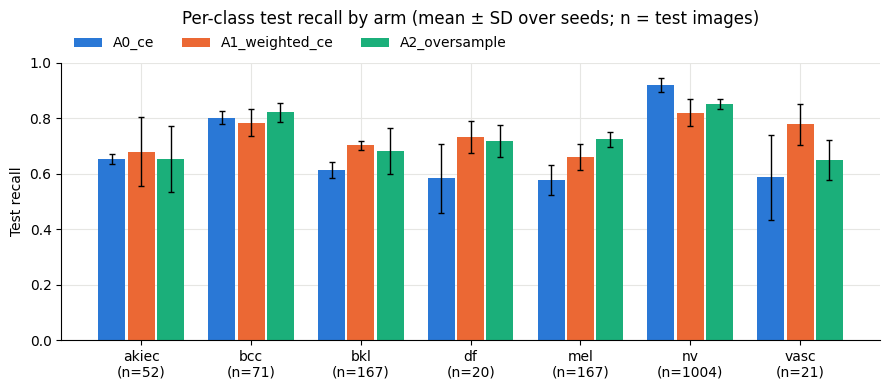

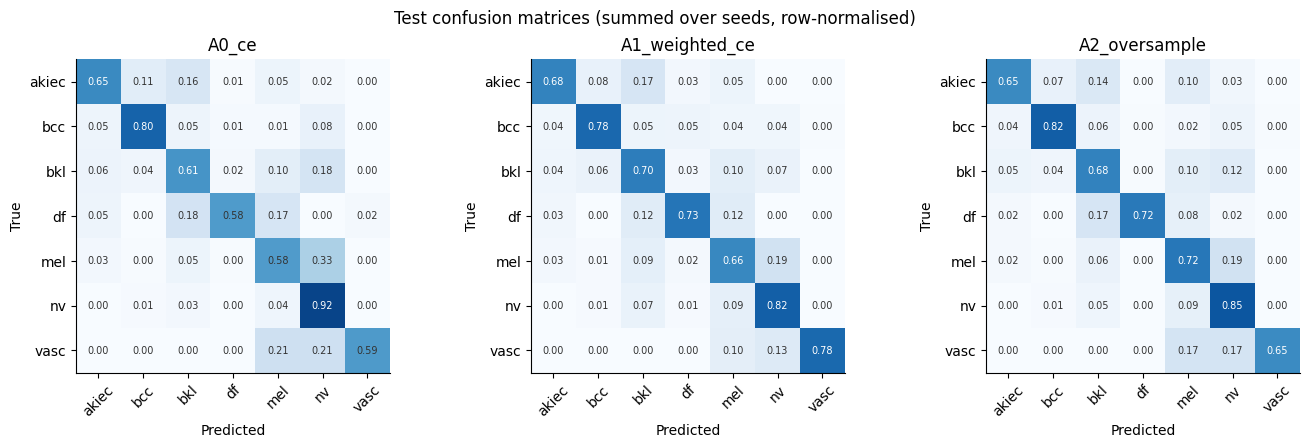

In [10]:
import matplotlib.pyplot as plt
FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)
ARM_COLORS = {"A0_ce": "#2a78d6", "A1_weighted_ce": "#eb6834", "A2_oversample": "#1baf7a"}  # fixed order, validated palette
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.8, "axes.axisbelow": True})

# Per-class test recall: mean over seeds, error bars = SD
arms = [a for a in CFG["ARMS"] if a in set(runs["arm"])]
x = np.arange(len(CLASSES)); w = 0.8 / max(len(arms), 1)
fig, ax = plt.subplots(figsize=(9, 4))
for k, a in enumerate(arms):
    sub = runs[runs["arm"] == a][[f"recall_{c}" for c in CLASSES]]
    ax.bar(x + (k - (len(arms) - 1) / 2) * w, sub.mean(), w * 0.92, yerr=sub.std().fillna(0),
           color=ARM_COLORS.get(a), label=a, capsize=2, error_kw={"elinewidth": 1})
support = DF["test"]["dx"].value_counts()
ax.set_xticks(x, [f"{c}\n(n={support.get(c, 0)})" for c in CLASSES])
ax.set_ylim(0, 1.0); ax.set_ylabel("Test recall")
ax.set_title("Per-class test recall by arm (mean ± SD over seeds; n = test images)", pad=28)
ax.legend(frameon=False, ncol=len(arms), loc="lower left", bbox_to_anchor=(0, 1.0))
fig.tight_layout(); fig.savefig(FIG / "per_class_recall.png", dpi=200); plt.show()

# Confusion matrices summed over seeds, row-normalised (share of each true class)
fig, axes = plt.subplots(1, len(arms), figsize=(4.6 * len(arms), 4.4), squeeze=False)
for ax, a in zip(axes[0], arms):
    cm = sum(np.array(json.loads(f.read_text())["test"]["confusion_matrix"])
             for f in (OUT / "runs").glob(f"{a}_seed*/metrics.json"))
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if cmn[i, j] > 0.6 else "#333333")
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45); ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(a)
fig.suptitle("Test confusion matrices (summed over seeds, row-normalised)")
fig.tight_layout(); fig.savefig(FIG / "confusion_matrices.png", dpi=200); plt.show()